In [327]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [328]:
df = pd.read_csv("alzheimers_disease_data.csv")

In [329]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  2149 non-null   int64  
 1   Age                        2149 non-null   int64  
 2   Gender                     2149 non-null   int64  
 3   Ethnicity                  2149 non-null   int64  
 4   EducationLevel             2149 non-null   int64  
 5   BMI                        2149 non-null   float64
 6   Smoking                    2149 non-null   int64  
 7   AlcoholConsumption         2149 non-null   float64
 8   PhysicalActivity           2149 non-null   float64
 9   DietQuality                2149 non-null   float64
 10  SleepQuality               2149 non-null   float64
 11  FamilyHistoryAlzheimers    2149 non-null   int64  
 12  CardiovascularDisease      2149 non-null   int64  
 13  Diabetes                   2149 non-null   int64

In [330]:
df.head()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,XXXConfid


In [331]:
df.describe()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
count,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,...,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000,2149.000000
mean,5825.000000,74.908795,0.506282,0.697534,1.286645,27.655697,0.288506,10.039442,4.920202,4.993138,...,5.080055,0.208004,0.156817,4.982958,0.205212,0.158213,0.150768,0.158678,0.301536,0.353653
std,620.507185,8.990221,0.500077,0.996128,0.904527,7.217438,0.453173,5.757910,2.857191,2.909055,...,2.892743,0.405974,0.363713,2.949775,0.403950,0.365026,0.357906,0.365461,0.459032,0.478214
min,4751.000000,60.000000,0.000000,0.000000,0.000000,15.008851,0.000000,0.002003,0.003616,0.009385,...,0.000460,0.000000,0.000000,0.001288,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5288.000000,67.000000,0.000000,0.000000,1.000000,21.611408,0.000000,5.139810,2.570626,2.458455,...,2.566281,0.000000,0.000000,2.342836,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5825.000000,75.000000,1.000000,0.000000,1.000000,27.823924,0.000000,9.934412,4.766424,5.076087,...,5.094439,0.000000,0.000000,5.038973,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,6362.000000,83.000000,1.000000,1.000000,2.000000,33.869778,1.000000,15.157931,7.427899,7.558625,...,7.546981,0.000000,0.000000,7.581490,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,6899.000000,90.000000,1.000000,3.000000,3.000000,39.992767,1.000000,19.989293,9.987429,9.998346,...,9.996467,1.000000,1.000000,9.999747,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [332]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  2149 non-null   int64  
 1   Age                        2149 non-null   int64  
 2   Gender                     2149 non-null   int64  
 3   Ethnicity                  2149 non-null   int64  
 4   EducationLevel             2149 non-null   int64  
 5   BMI                        2149 non-null   float64
 6   Smoking                    2149 non-null   int64  
 7   AlcoholConsumption         2149 non-null   float64
 8   PhysicalActivity           2149 non-null   float64
 9   DietQuality                2149 non-null   float64
 10  SleepQuality               2149 non-null   float64
 11  FamilyHistoryAlzheimers    2149 non-null   int64  
 12  CardiovascularDisease      2149 non-null   int64  
 13  Diabetes                   2149 non-null   int64

In [333]:
df.duplicated().sum()

0

In [334]:
df.isnull().sum()

PatientID                    0
Age                          0
Gender                       0
Ethnicity                    0
EducationLevel               0
BMI                          0
Smoking                      0
AlcoholConsumption           0
PhysicalActivity             0
DietQuality                  0
SleepQuality                 0
FamilyHistoryAlzheimers      0
CardiovascularDisease        0
Diabetes                     0
Depression                   0
HeadInjury                   0
Hypertension                 0
SystolicBP                   0
DiastolicBP                  0
CholesterolTotal             0
CholesterolLDL               0
CholesterolHDL               0
CholesterolTriglycerides     0
MMSE                         0
FunctionalAssessment         0
MemoryComplaints             0
BehavioralProblems           0
ADL                          0
Confusion                    0
Disorientation               0
PersonalityChanges           0
DifficultyCompletingTasks    0
Forgetfu

In [335]:
df = df.drop(columns=['PatientID', 'DoctorInCharge'])

In [336]:
df['Diagnosis'].value_counts()

Diagnosis
0    1389
1     760
Name: count, dtype: int64

In [337]:
df.head()

,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
0,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,9.025679,...,6.518877,0,0,1.725883,0,0,0,1,0,0
1,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,7.151293,...,7.118696,0,0,2.592424,0,0,0,0,1,0
2,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,9.673574,...,5.895077,0,0,7.119548,0,1,0,1,0,0
3,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,8.392554,...,8.965106,0,1,6.481226,0,0,0,0,0,0
4,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,5.597238,...,6.045039,0,0,0.014691,0,0,1,1,0,0


In [338]:
x = df.drop('Diagnosis', axis=1)
y = df['Diagnosis']

In [339]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 32 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Age                        2149 non-null   int64  
 1   Gender                     2149 non-null   int64  
 2   Ethnicity                  2149 non-null   int64  
 3   EducationLevel             2149 non-null   int64  
 4   BMI                        2149 non-null   float64
 5   Smoking                    2149 non-null   int64  
 6   AlcoholConsumption         2149 non-null   float64
 7   PhysicalActivity           2149 non-null   float64
 8   DietQuality                2149 non-null   float64
 9   SleepQuality               2149 non-null   float64
 10  FamilyHistoryAlzheimers    2149 non-null   int64  
 11  CardiovascularDisease      2149 non-null   int64  
 12  Diabetes                   2149 non-null   int64  
 13  Depression                 2149 non-null   int64

In [340]:
y.info()

<class 'pandas.core.series.Series'>
RangeIndex: 2149 entries, 0 to 2148
Series name: Diagnosis
Non-Null Count  Dtype
--------------  -----
2149 non-null   int64
dtypes: int64(1)
memory usage: 16.9 KB


In [341]:
y.value_counts()

Diagnosis
0    1389
1     760
Name: count, dtype: int64

In [342]:
df.corr()

,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
Age,1.000000,0.028708,0.027745,-0.060560,-0.015677,0.020060,0.007323,-0.010249,-0.023386,0.049139,...,0.005508,0.012343,0.038973,-0.038658,0.009002,0.027523,-0.009470,0.013900,-0.019279,-0.005488
Gender,0.028708,1.000000,-0.003660,-0.007070,0.005928,0.016650,0.004330,-0.035795,0.010942,0.007310,...,0.033324,0.003880,0.006099,0.003865,-0.030583,0.017506,0.025919,-0.001636,-0.028537,-0.020975
Ethnicity,0.027745,-0.003660,1.000000,0.026516,-0.003176,0.031485,0.008363,0.020498,-0.018184,0.029304,...,-0.004704,0.003687,-0.019363,0.010475,0.022431,-0.018132,-0.030035,0.019363,-0.034619,-0.014782
EducationLevel,-0.060560,-0.007070,0.026516,1.000000,-0.023514,-0.009904,-0.012646,-0.016703,0.017412,0.020248,...,0.020269,-0.000165,0.010473,0.031934,-0.008168,-0.017568,-0.019950,0.013033,-0.008685,-0.043966
BMI,-0.015677,0.005928,-0.003176,-0.023514,1.000000,0.020437,-0.008997,0.000742,0.019922,-0.005975,...,-0.030501,0.029293,0.035276,-0.009788,-0.015859,-0.031840,-0.015901,-0.039400,0.071131,0.026343
Smoking,0.020060,0.016650,0.031485,-0.009904,0.020437,1.000000,0.008363,0.010760,-0.002048,-0.001145,...,-0.031879,0.020339,-0.014763,-0.029233,0.004498,-0.028403,-0.009977,0.001741,0.018011,-0.004865
AlcoholConsumption,0.007323,0.004330,0.008363,-0.012646,-0.008997,0.008363,1.000000,0.021696,0.020117,-0.003873,...,-0.016483,-0.029418,0.013657,-0.008250,-0.032798,0.015521,0.019117,-0.002712,-0.024121,-0.007618
PhysicalActivity,-0.010249,-0.035795,0.020498,-0.016703,0.000742,0.010760,0.021696,1.000000,0.011085,-0.001823,...,-0.002419,0.008709,-0.014253,-0.013324,-0.009397,-0.020407,-0.013629,0.031169,0.009837,0.005945
DietQuality,-0.023386,0.010942,-0.018184,0.017412,0.019922,-0.002048,0.020117,0.011085,1.000000,0.051295,...,-0.009700,0.012537,-0.014033,-0.007888,0.002628,-0.026271,0.029087,0.045737,0.006175,0.008506
SleepQuality,0.049139,0.007310,0.029304,0.020248,-0.005975,-0.001145,-0.003873,-0.001823,0.051295,1.000000,...,0.029589,-0.016807,-0.019899,0.014535,0.013508,0.019467,-0.016892,0.011237,0.002930,-0.056548


<Axes: >

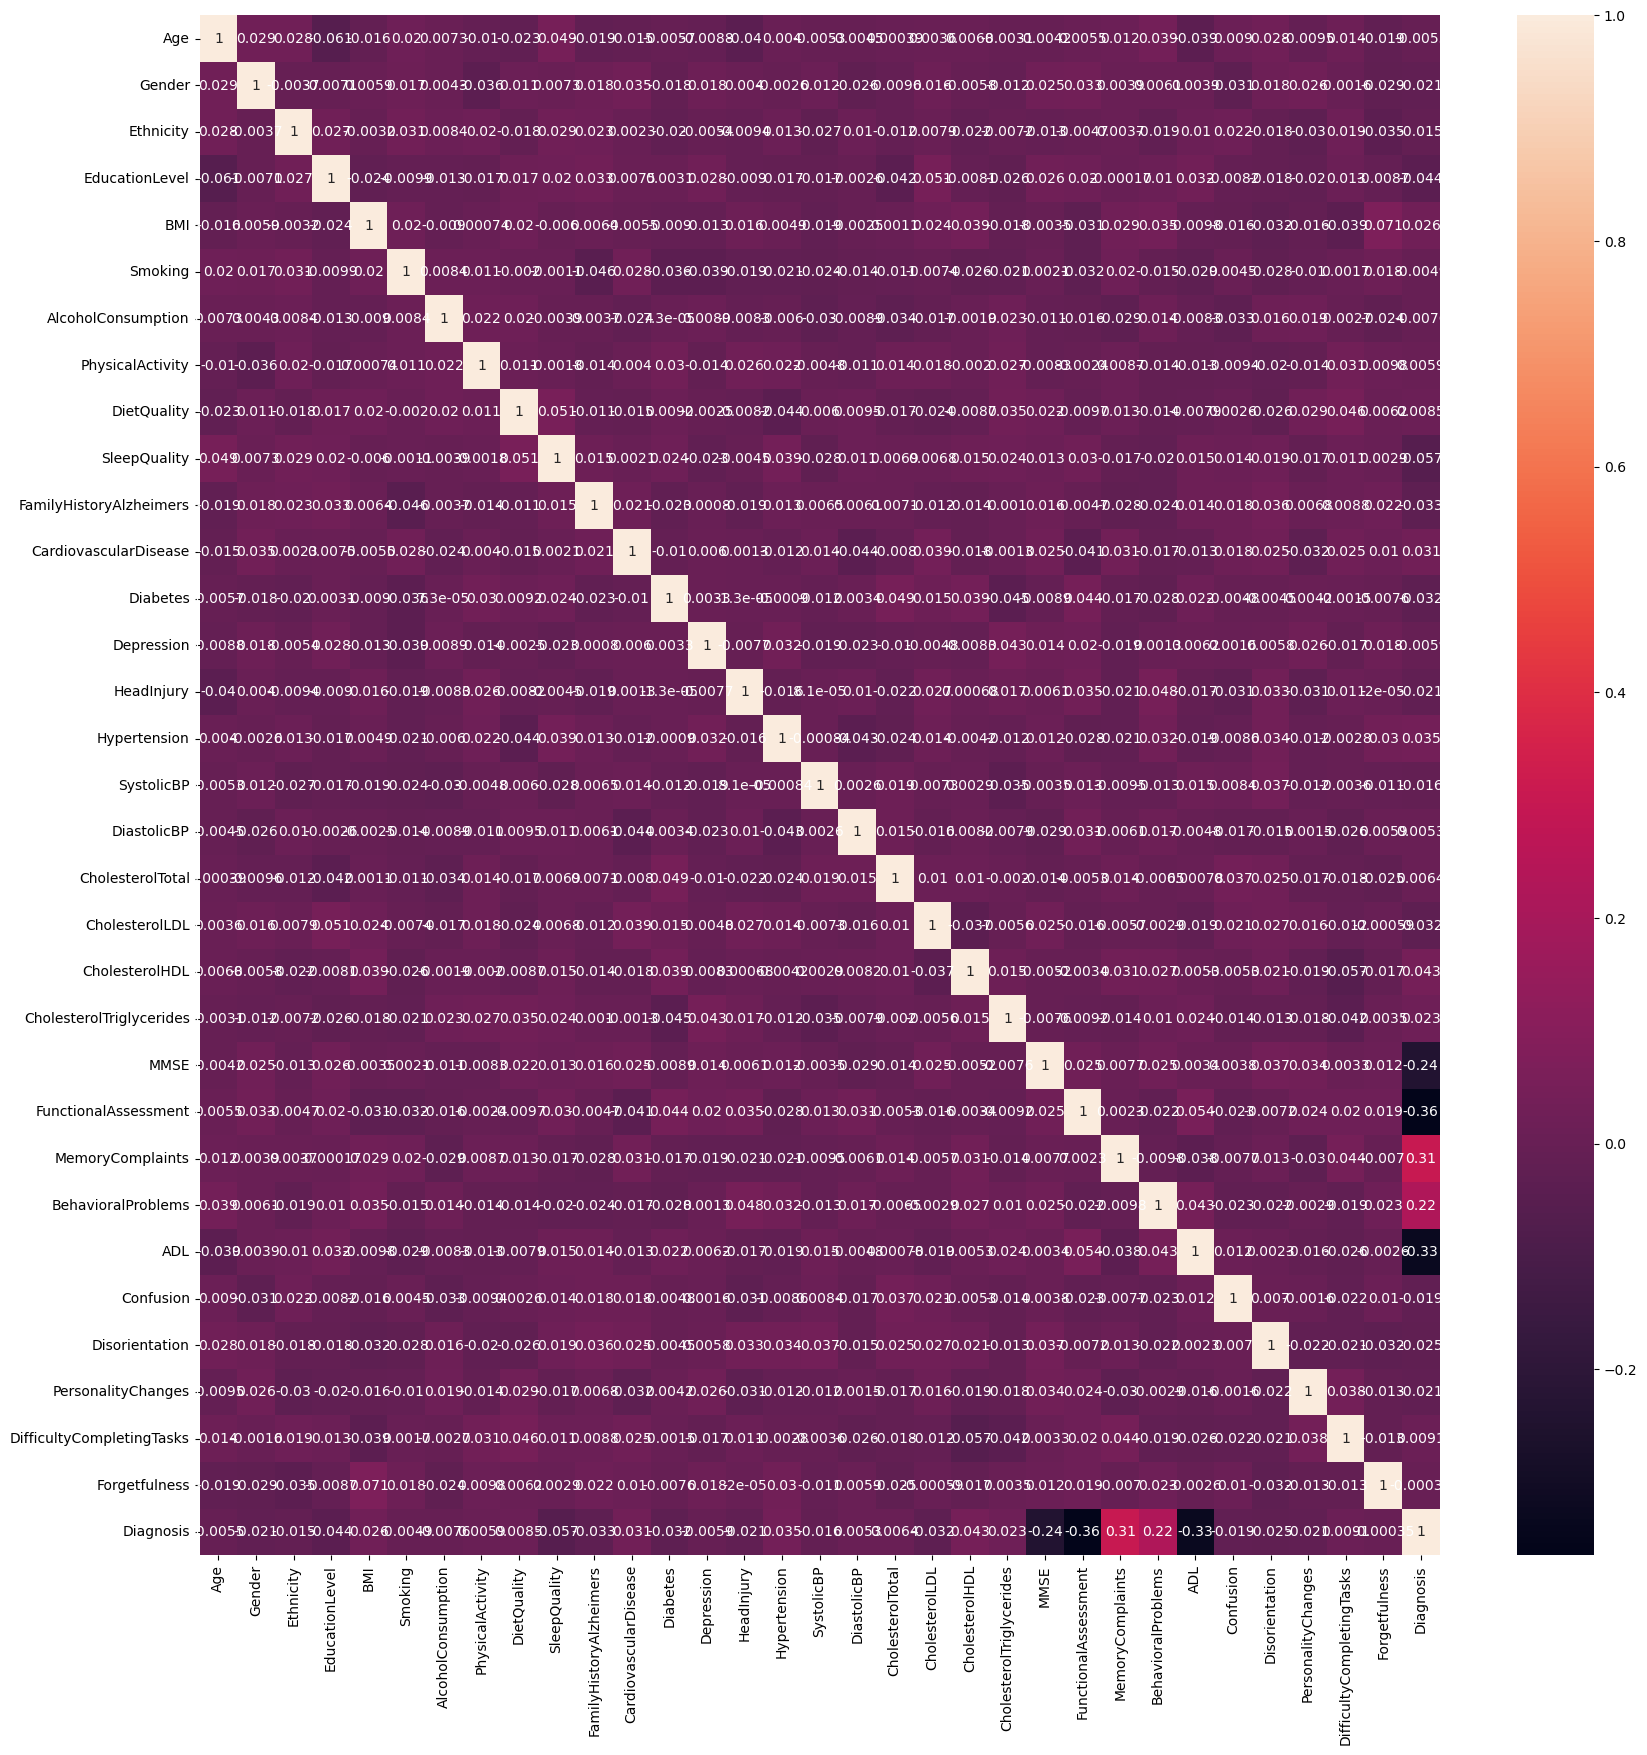

In [343]:
plt.figure(figsize=(20,20))
sns.heatmap(df.corr(), annot=True)

In [344]:
y.value_counts()

Diagnosis
0    1389
1     760
Name: count, dtype: int64

In [345]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [346]:
#apply smote to remove biasness

In [347]:
y_train.value_counts()

Diagnosis
0    1112
1     607
Name: count, dtype: int64

In [348]:
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# 1. Define numerical features
num_cols = [
    'Age', 'BMI', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 
    'SleepQuality', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 
    'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 
    'MMSE', 'FunctionalAssessment', 'ADL'
]

# 2. Fit scaler ONLY on training data
scaler = StandardScaler()

x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

x_train_scaled[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test_scaled[num_cols] = scaler.transform(x_test[num_cols])

# 3. Apply SMOTE ONLY on scaled & unscaled training sets
smote = SMOTE(sampling_strategy='minority', random_state=42)

# Resampled scaled training data (for LR, KNN)
x_train_scaled_res, y_train_res = smote.fit_resample(x_train_scaled, y_train)

# Resampled unscaled training data (for DT, RF, XGBoost)
x_train_res, _ = smote.fit_resample(x_train, y_train)

In [349]:
y_train.value_counts()

Diagnosis
0    1112
1     607
Name: count, dtype: int64

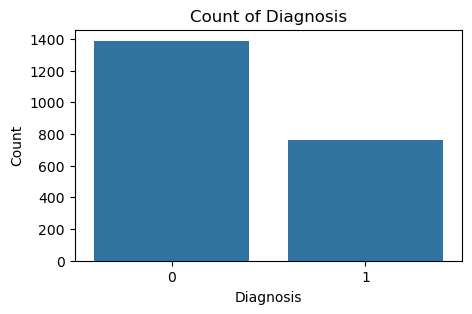

In [350]:
plt.figure(figsize=(5,3))
sns.countplot(x=y)
plt.title('Count of Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.show()

In [351]:
# Logistic Regression (Distance-based -> uses scaled + resampled)
lr = LogisticRegression()
lr.fit(x_train_scaled_res, y_train_res)

# Decision Tree (Tree-based -> uses unscaled + resampled)
dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_train_res, y_train_res)

# Random Forest (Tree-based -> uses unscaled + resampled)
rf = RandomForestClassifier(random_state=42)
rf.fit(x_train_res, y_train_res)

# KNN (Distance-based -> uses scaled + resampled)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled_res, y_train_res)

KNeighborsClassifier()

In [352]:
lr_pred = lr.predict(x_test_scaled)
print("lr: ", lr.score(x_test_scaled, y_test))

rf_pred = rf.predict(x_test)
print("rf: ", rf.score(x_test, y_test))

dt_pred = dt.predict(x_test)
print("dt: ", dt.score(x_test, y_test))

knn_pred = knn.predict(x_test_scaled)
print("knn: ", knn.score(x_test_scaled, y_test))

lr:  0.813953488372093
rf:  0.9093023255813953
dt:  0.8441860465116279
knn:  0.6325581395348837


              precision    recall  f1-score   support

           0       0.87      0.83      0.85       277
           1       0.72      0.78      0.75       153

    accuracy                           0.81       430
   macro avg       0.80      0.81      0.80       430
weighted avg       0.82      0.81      0.82       430



<Axes: >

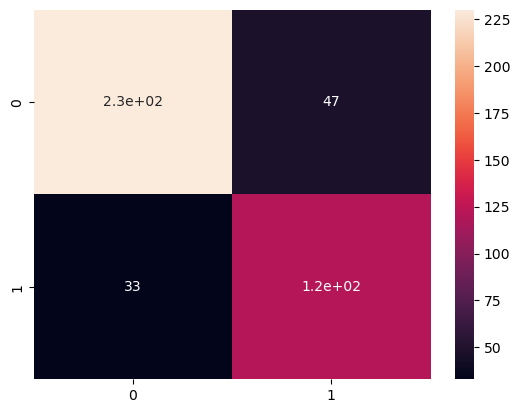

In [353]:
from sklearn.metrics import confusion_matrix, classification_report
print(classification_report(y_test, lr_pred))
cm = confusion_matrix(y_test, lr_pred)
sns.heatmap(cm, annot=True)

              precision    recall  f1-score   support

           0       0.90      0.97      0.93       277
           1       0.93      0.80      0.86       153

    accuracy                           0.91       430
   macro avg       0.92      0.89      0.90       430
weighted avg       0.91      0.91      0.91       430

[[268   9]
 [ 30 123]]


<Axes: >

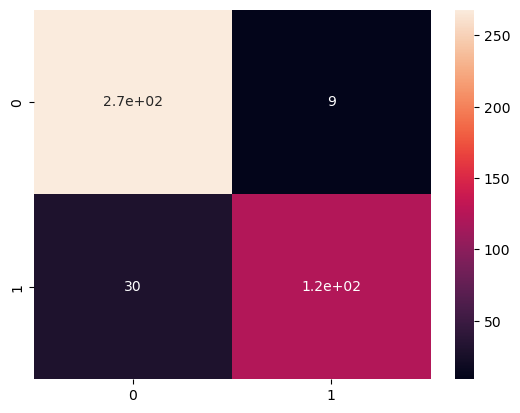

In [354]:
print(classification_report(y_test, rf_pred))
cm2 = confusion_matrix(y_test, rf_pred)
print(cm2)
sns.heatmap(cm2, annot=True)

              precision    recall  f1-score   support

           0       0.92      0.83      0.87       277
           1       0.74      0.86      0.80       153

    accuracy                           0.84       430
   macro avg       0.83      0.85      0.84       430
weighted avg       0.85      0.84      0.85       430



<Axes: >

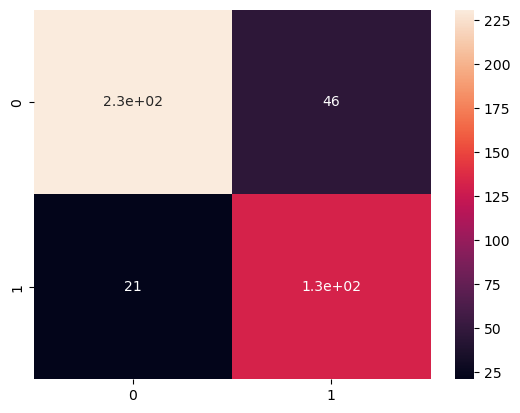

In [355]:
print(classification_report(y_test, dt_pred))
cm3 = confusion_matrix(y_test, dt_pred)
sns.heatmap(cm3, annot=True)

              precision    recall  f1-score   support

           0       0.81      0.56      0.66       277
           1       0.49      0.76      0.59       153

    accuracy                           0.63       430
   macro avg       0.65      0.66      0.63       430
weighted avg       0.69      0.63      0.64       430



<Axes: >

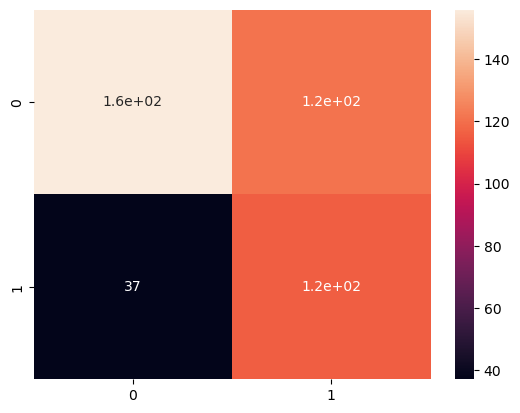

In [356]:
print(classification_report(y_test, knn_pred))
cm4 = confusion_matrix(y_test, knn_pred)
sns.heatmap(cm4, annot=True)

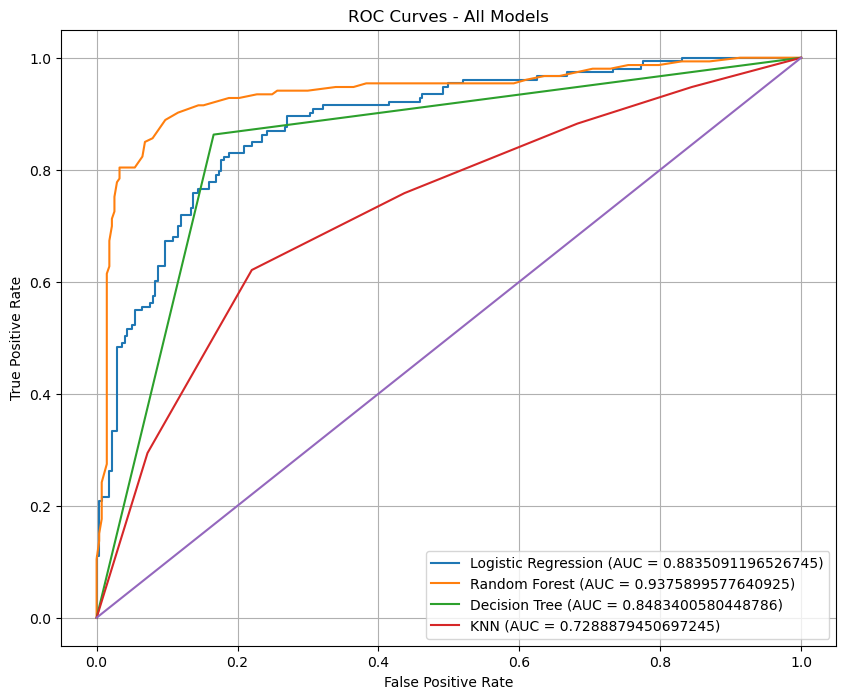

In [357]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Prepare figure
plt.figure(figsize=(10, 8))

# 1. Logistic Regression
y_pred_prob_lr = lr.predict_proba(x_test_scaled)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_prob_lr)
auc_lr = roc_auc_score(y_test, y_pred_prob_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr})')

# 2. Random Forest
y_pred_prob_rf = rf.predict_proba(x_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_prob_rf)
auc_rf = roc_auc_score(y_test, y_pred_prob_rf)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf})')

# 3. Decision Tree
y_pred_prob_dt = dt.predict_proba(x_test)[:, 1]
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_prob_dt)
auc_dt = roc_auc_score(y_test, y_pred_prob_dt)
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt})')

#4. KNN
y_pred_prob_knn = knn.predict_proba(x_test_scaled)[:, 1]
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_pred_prob_knn)
auc_knn = roc_auc_score(y_test, y_pred_prob_knn)
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {auc_knn})')

# Plot Diagonal line
plt.plot([0, 1], [0, 1])

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [358]:
#GRADIENTBOOST-finds the errors in datasets and works on them to improve accuracy in the dataset

In [359]:
#ADABOOST- finds the error and asigns a weight to them so that error correction an should work based on higher weight

In [360]:
#XGBOOSTING- finds error in it assigns weight to them and panelty as well

In [361]:
!pip install xgboost

In [362]:
from xgboost import XGBClassifier

# Train XGBoost on resampled training data
xgb = XGBClassifier(random_state=42)
xgb.fit(x_train_res, y_train_res)

xgb_predict = xgb.predict(x_test)

In [363]:
xgb.score(x_test, y_test)

0.9255813953488372

cf report               precision    recall  f1-score   support

           0       0.94      0.94      0.94       277
           1       0.90      0.90      0.90       153

    accuracy                           0.93       430
   macro avg       0.92      0.92      0.92       430
weighted avg       0.93      0.93      0.93       430



<Axes: >

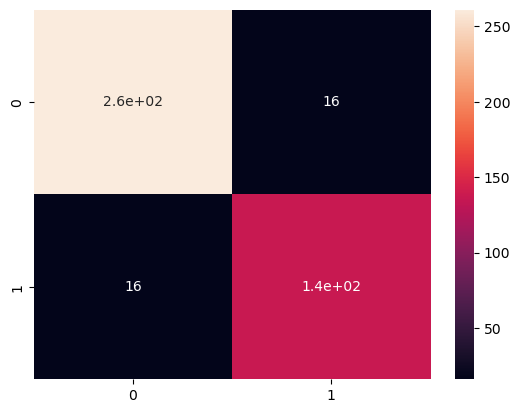

In [364]:
print("cf report", classification_report(y_test, xgb_predict))
cm5 = confusion_matrix(y_test, xgb_predict)
sns.heatmap(cm5, annot=True)

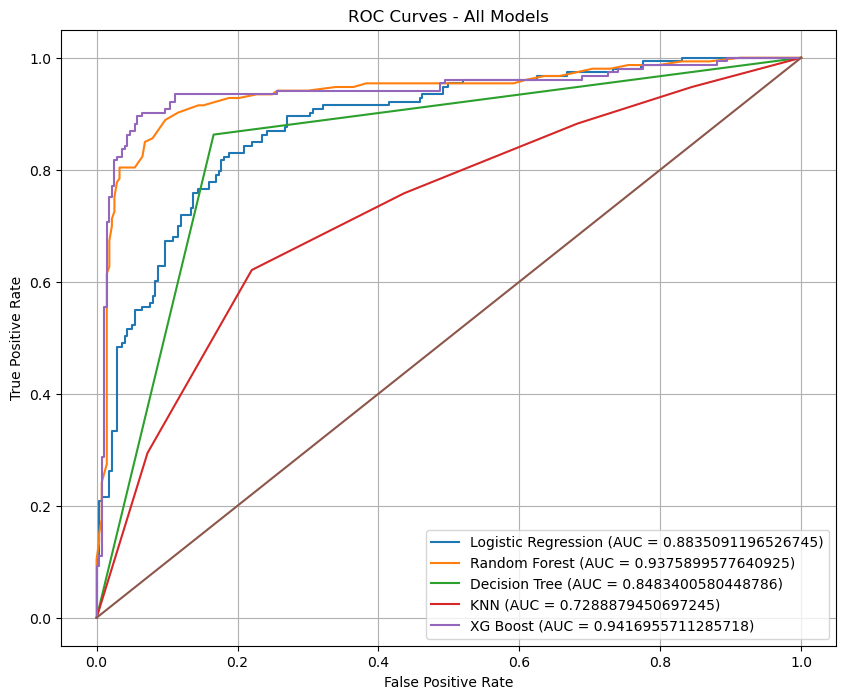

In [365]:
# Prepare figure
plt.figure(figsize=(10, 8))

# 1. Logistic Regression
y_pred_prob_lr = lr.predict_proba(x_test_scaled)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_prob_lr)
auc_lr = roc_auc_score(y_test, y_pred_prob_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr})')

# 2. Random Forest
y_pred_prob_rf = rf.predict_proba(x_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_prob_rf)
auc_rf = roc_auc_score(y_test, y_pred_prob_rf)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf})')

# 3. Decision Tree
y_pred_prob_dt = dt.predict_proba(x_test)[:, 1]
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_prob_dt)
auc_dt = roc_auc_score(y_test, y_pred_prob_dt)
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt})')

#4. KNN
y_pred_prob_knn = knn.predict_proba(x_test_scaled)[:, 1]
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_pred_prob_knn)
auc_knn = roc_auc_score(y_test, y_pred_prob_knn)
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {auc_knn})')

#5. xgboost
y_pred_prob_xgb = xgb.predict_proba(x_test)[:, 1]
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_prob_xgb)
auc_xgb = roc_auc_score(y_test, y_pred_prob_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f'XG Boost (AUC = {auc_xgb})')

# Plot Diagonal line
plt.plot([0, 1], [0, 1])

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()